In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error,r2_score

## Using get dummies

In [102]:
import os
os.chdir("E:/Vishal_Adesh/Machine Learning/Datasets")

In [103]:
df = pd.read_csv("Housing.csv")

In [104]:
df.head()

,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,42000.0,5850,3,1,2,yes,no,yes,no,no,1,no
1,38500.0,4000,2,1,1,yes,no,no,no,no,0,no
2,49500.0,3060,3,1,1,yes,no,no,no,no,0,no
3,60500.0,6650,3,1,2,yes,yes,no,no,no,0,no
4,61000.0,6360,2,1,1,yes,no,no,no,no,0,no


In [105]:
dum_house = pd.get_dummies(df, drop_first=True)
X, y = dum_house.drop('price',axis=1),dum_house['price']
X_train, X_test, y_train, y_test = train_test_split(X,y, random_state=26, test_size=0.3)
lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

In [106]:
dum_house

,price,lotsize,bedrooms,bathrms,stories,garagepl,driveway_yes,recroom_yes,fullbase_yes,gashw_yes,airco_yes,prefarea_yes
0,42000.0,5850,3,1,2,1,True,False,True,False,False,False
1,38500.0,4000,2,1,1,0,True,False,False,False,False,False
2,49500.0,3060,3,1,1,0,True,False,False,False,False,False
3,60500.0,6650,3,1,2,0,True,True,False,False,False,False
4,61000.0,6360,2,1,1,0,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
541,91500.0,4800,3,2,4,0,True,True,False,False,True,False
542,94000.0,6000,3,2,4,0,True,False,False,False,True,False
543,103000.0,6000,3,2,4,1,True,True,False,False,True,False
544,105000.0,6000,3,2,2,1,True,True,False,False,True,False


In [107]:
r2_score(y_test,y_pred)

0.6791781818067916

In [108]:
housing_test = pd.read_csv("tst_Housing.csv")
housing_test

,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,5600,3,1,2,yes,no,yes,no,no,1,no
1,4355,2,1,1,yes,no,no,no,no,0,no
2,3412,3,1,1,yes,no,no,no,no,0,no
3,6666,2,2,2,yes,yes,no,no,no,0,no


In [109]:
dum_house_test = pd.get_dummies(housing_test)

In [110]:
dum_house_test = dum_house_test.reindex(columns=dum_house.columns, fill_value=0)

In [111]:
dum_house_test

,price,lotsize,bedrooms,bathrms,stories,garagepl,driveway_yes,recroom_yes,fullbase_yes,gashw_yes,airco_yes,prefarea_yes
0,0,5600,3,1,2,1,True,False,True,0,0,0
1,0,4355,2,1,1,0,True,False,False,0,0,0
2,0,3412,3,1,1,0,True,False,False,0,0,0
3,0,6666,2,2,2,0,True,True,False,0,0,0


In [112]:
dum_house_test = dum_house_test.drop(columns=["price"], errors="ignore")

In [113]:
y_pred = lr.predict(dum_house_test)

In [114]:
y_pred

array([66460.25330163, 42714.87464687, 40469.90014429, 75958.60712357])

<Axes: >

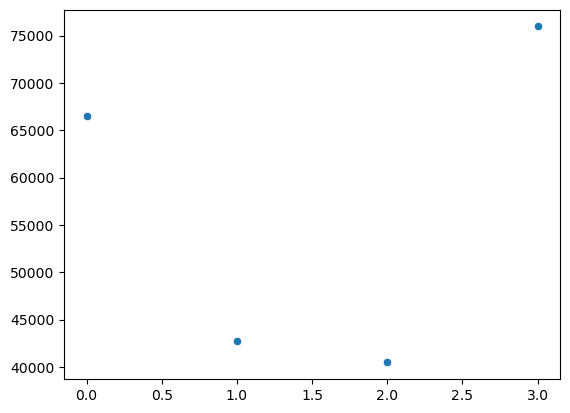

In [115]:
sns.scatterplot(y_pred)

# Using OHE

In [116]:
from sklearn.compose import make_column_selector,make_column_transformer

In [101]:
df_test = pd.read_csv("tst_Housing.csv")
df_test

,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,5600,3,1,2,yes,no,yes,no,no,1,no
1,4355,2,1,1,yes,no,no,no,no,0,no
2,3412,3,1,1,yes,no,no,no,no,0,no
3,6666,2,2,2,yes,yes,no,no,no,0,no


In [117]:
df

,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,42000.0,5850,3,1,2,yes,no,yes,no,no,1,no
1,38500.0,4000,2,1,1,yes,no,no,no,no,0,no
2,49500.0,3060,3,1,1,yes,no,no,no,no,0,no
3,60500.0,6650,3,1,2,yes,yes,no,no,no,0,no
4,61000.0,6360,2,1,1,yes,no,no,no,no,0,no
...,...,...,...,...,...,...,...,...,...,...,...,...
541,91500.0,4800,3,2,4,yes,yes,no,no,yes,0,no
542,94000.0,6000,3,2,4,yes,no,no,no,yes,0,no
543,103000.0,6000,3,2,4,yes,yes,no,no,yes,1,no
544,105000.0,6000,3,2,2,yes,yes,no,no,yes,1,no


In [123]:
ohc = OneHotEncoder(sparse_output=False, handle_unknown='ignore',drop="first").set_output(transform='pandas')
ct = make_column_transformer((ohc,make_column_selector(dtype_include=object)),('passthrough', make_column_selector(dtype_include=["int64","float64"])),verbose_feature_names_out=False)
ct = ct.set_output(transform='pandas')
X_ohe = ct.fit_transform(X)
X, y = df.drop('price',axis=1),df['price']
X_train, X_test, y_train, y_test = train_test_split(X,y, random_state=26, test_size=0.3)
lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
r2_score(y_test,y_pred)

ValueError: could not convert string to float: 'yes'

In [ ]:
 #fit transform to be applied on labeled data .tranform to be applied on unlabeled data

In [124]:


X = df.drop("price", axis=1)
y = df["price"]

X_transformed = ct.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_transformed, y, random_state=26, test_size=0.3)

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.6791781818068097


In [125]:
housing = pd.read_csv("Housing.csv")
housing.head()

,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,42000.0,5850,3,1,2,yes,no,yes,no,no,1,no
1,38500.0,4000,2,1,1,yes,no,no,no,no,0,no
2,49500.0,3060,3,1,1,yes,no,no,no,no,0,no
3,60500.0,6650,3,1,2,yes,yes,no,no,no,0,no
4,61000.0,6360,2,1,1,yes,no,no,no,no,0,no


In [132]:
tst_housing = pd.read_csv("tst_Housing.csv")
tst_housing

,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,5600,3,1,2,yes,no,yes,no,no,1,no
1,4355,2,1,1,yes,no,no,no,no,0,no
2,3412,3,1,1,yes,no,no,no,no,0,no
3,6666,2,2,2,yes,yes,no,no,no,0,no


In [131]:
ohc = OneHotEncoder(sparse_output=False, handle_unknown='ignore',drop="first").set_output(transform='pandas')
ct = make_column_transformer((ohc,make_column_selector(dtype_include=object)),('passthrough', make_column_selector(dtype_include=["int64","float64"])),verbose_feature_names_out=False)
ct = ct.set_output(transform='pandas')
X_ohe = ct.fit_transform(X)
X,y = housing.drop('price',axis=1),housing['price']
X_train, X_test, y_train, y_test = train_test_split(X_ohe,y, random_state=26, test_size=0.3)
lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
r2_score(y_test,y_pred)

0.6791781818068097

In [139]:
X, y = housing.drop('price', axis=1), housing['price']
X_train , X_test , y_train, y_test = train_test_split(X,y,random_state = 26 , test_size = 0.3)

ohc = OneHotEncoder(sparse_output = False, drop = 'first').set_output(transform = 'pandas')

ct = make_column_transformer(
                            (ohc, make_column_selector(dtype_include = object)),
                            ('passthrough', make_column_selector(dtype_include =['int64','float64'])),
                             verbose_feature_names_out = False)
ct = ct.set_output(transform = 'pandas')
x_ohe = ct.fit_transform(X_train)
x_ohe


,driveway_yes,recroom_yes,fullbase_yes,gashw_yes,airco_yes,prefarea_yes,lotsize,bedrooms,bathrms,stories,garagepl
40,1.0,0.0,1.0,0.0,0.0,0.0,3745,3,1,2,0
197,0.0,0.0,0.0,1.0,0.0,0.0,4350,3,1,2,1
48,0.0,0.0,0.0,0.0,0.0,0.0,4960,4,1,3,0
67,1.0,0.0,1.0,0.0,1.0,0.0,6000,2,1,1,1
26,1.0,0.0,0.0,0.0,0.0,0.0,3800,2,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
160,1.0,0.0,0.0,0.0,1.0,0.0,3162,3,1,2,1
77,1.0,0.0,1.0,0.0,1.0,0.0,3180,4,1,2,0
102,1.0,0.0,1.0,1.0,0.0,0.0,4320,3,1,2,2
432,1.0,0.0,0.0,0.0,0.0,1.0,6040,3,1,1,2


In [140]:
r2_score(y_test,y_pred)

0.6791781818068097

In [141]:
lr = LinearRegression()
lr.fit(x_ohe, y_train)

X_test_transf = ct.transform(X_test)

y_pred = lr.predict(X_test_transf)
r2score = r2_score(y_test,y_pred)
r2score

0.6791781818068097